In [2]:
import os
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # data and annotation paths are relative to the repository root

import numpy as np

import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import datetime
import glob
import json
import cv2
from matplotlib.colors import Normalize

## 1. Load the data

In [3]:
def set_axis(x, no_labels = 7)->tuple[np.array, np.array]:
    """Sets the x-axis positions and labels for a plot.

    Args:
        x (np.array): The x-axis data.
        no_labels (int, optional): The number of labels to display. Defaults to 7.

    Returns:
        tuple[np.array, np.array]: A tuple containing:
            - The positions of the labels on the x-axis.
            - The labels themselves.
    """
    nx = x.shape[0]
    step_x = int(nx / (no_labels - 1)) 
    x_positions = np.arange(0,nx,step_x) 
    x_labels = x[::step_x]
    return x_positions, x_labels



DX = 5.106500953873407
DT = 0.0016


def read_das_file(files):
    data = np.concatenate([np.load(f) for f in files])
    time_start = datetime.datetime.strptime('2024-05-07 ' + files[0][-10:-4], "%Y-%m-%d %H%M%S")
    index = pd.date_range(start=time_start, periods=len(data), freq=f'{DT}s')
    columns = np.arange(len(data[0])) * DX
    return pd.DataFrame(data=data, index=index, columns=columns)

files = sorted(glob.glob('real-world-data/*.npy'))
df_real = read_das_file([f for f in files if '091052' <= f[-10:-4] <= '091242'])
df_real

files2 = sorted(glob.glob('real-world-data/*.npy'))
df_real2 = read_das_file([f for f in files2 if '091152' <= f[-10:-4] <= '091342'])
df_real2

,0.000000,5.106501,10.213002,15.319503,20.426004,25.532505,30.639006,35.745507,40.852008,45.958509,...,214.473040,219.579541,224.686042,229.792543,234.899044,240.005545,245.112046,250.218547,255.325048,260.431549
2024-05-07 09:11:52.000000,9.049309e-07,8.898905e-07,3.559562e-07,3.008080e-07,4.060909e-07,5.013467e-07,4.060909e-07,4.913198e-07,5.439612e-07,3.384091e-07,...,-2.456599e-07,1.128030e-07,1.829916e-07,-3.760100e-08,-1.052828e-07,-1.027761e-07,-1.854983e-07,-1.203232e-07,1.278434e-07,1.754714e-07
2024-05-07 09:11:52.001600,7.520201e-07,8.573030e-07,2.882744e-07,2.431532e-07,3.985706e-07,4.687592e-07,3.634764e-07,4.787861e-07,4.863064e-07,8.522895e-08,...,1.178165e-07,4.186245e-07,3.183552e-07,-2.506734e-08,-1.002693e-07,-7.770875e-08,-2.030454e-07,-2.256060e-07,-5.514814e-08,3.509427e-08
2024-05-07 09:11:52.003200,6.191632e-07,7.670605e-07,1.478973e-07,1.353636e-07,3.860370e-07,4.236380e-07,3.233687e-07,4.436919e-07,3.384091e-07,2.431532e-07,...,3.584629e-07,6.692979e-07,3.735033e-07,-6.768181e-08,-1.278434e-07,-1.328569e-07,-2.030454e-07,-1.303502e-07,-1.754714e-08,-6.768181e-08
2024-05-07 09:11:52.004800,4.662525e-07,6.667912e-07,6.266834e-08,6.768181e-08,3.459293e-07,3.008080e-07,1.729646e-07,3.409158e-07,4.361717e-07,2.832609e-07,...,3.559562e-07,5.765488e-07,2.707272e-07,-9.776262e-08,-4.261447e-08,3.760100e-08,-2.581936e-07,-3.258754e-07,-1.178165e-07,-1.554175e-07
2024-05-07 09:11:52.006400,2.581936e-07,4.537188e-07,-7.269528e-08,5.514814e-08,4.085976e-07,2.306195e-07,1.453906e-07,4.035841e-07,3.033148e-07,1.328569e-07,...,1.353636e-07,4.236380e-07,3.534495e-07,-4.010774e-08,-2.757407e-07,-2.356330e-07,-1.579242e-07,-1.905118e-07,-2.632070e-07,-2.531801e-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-05-07 09:13:51.992000,5.489747e-07,3.835302e-07,1.453906e-07,2.155791e-07,3.735033e-07,4.286515e-07,-4.010774e-08,-4.737727e-07,-1.052828e-07,3.283821e-07,...,5.264141e-08,-1.278434e-07,-1.102963e-07,1.754714e-08,-8.021548e-08,-1.102963e-07,-9.024242e-08,-4.261447e-08,8.272221e-08,1.303502e-07
2024-05-07 09:13:51.993600,5.013467e-07,3.584629e-07,9.525588e-08,2.431532e-07,4.787861e-07,4.762794e-07,0.000000e+00,-4.211313e-07,-1.102963e-07,1.128030e-07,...,2.506734e-08,-3.258754e-08,-1.504040e-08,-1.754714e-08,-7.269528e-08,-7.018854e-08,-5.013467e-08,-1.002693e-08,4.762794e-08,-4.261447e-08
2024-05-07 09:13:51.995200,4.286515e-07,2.556868e-07,-2.506734e-08,1.854983e-07,4.938265e-07,4.963333e-07,8.021548e-08,-3.509427e-07,-2.256060e-07,7.269528e-08,...,-1.128030e-07,-1.027761e-07,-4.261447e-08,2.506734e-08,-2.506734e-09,-6.768181e-08,-6.266834e-08,-4.261447e-08,5.013467e-09,-1.002693e-08
2024-05-07 09:13:51.996800,3.409158e-07,2.381397e-07,1.253367e-08,5.264141e-08,2.907811e-07,4.938265e-07,1.980320e-07,-2.406464e-07,-1.754714e-07,7.770875e-08,...,-1.880050e-07,-1.905118e-07,-5.514814e-08,1.253367e-08,-6.768181e-08,-1.002693e-07,-7.269528e-08,-5.013467e-08,0.000000e+00,8.272221e-08


In [4]:
synthetic = {}
for i in range(40, 46):
    signal = np.load(f'synthetic-data/{i}_signal.npy')
    index = np.arange(len(signal)) * DT
    columns = np.arange(signal.shape[1]) * DX
    synthetic[i] = {
        'signal': pd.DataFrame(signal, index=index, columns=columns),
        'ground_truth': pd.DataFrame(np.load(f'synthetic-data/{i}_ground_truth.npy'), index=index, columns=columns),
        'vehicles': pd.DataFrame(json.load(open(f'synthetic-data/{i}_metadata.json'))['ground_truth']['vehicles']).set_index('marker_value'),
    }

## 2. Analyze the dataset

### 2.1 Distribution of the values

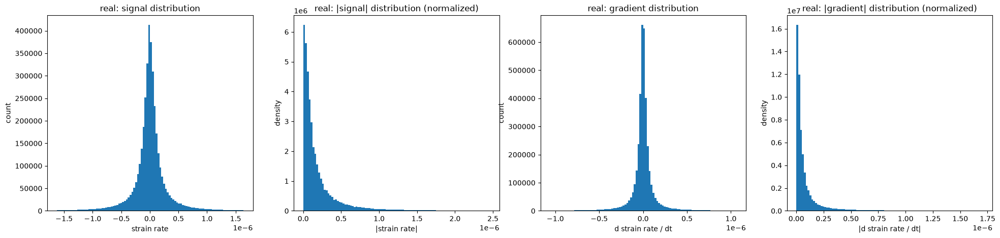

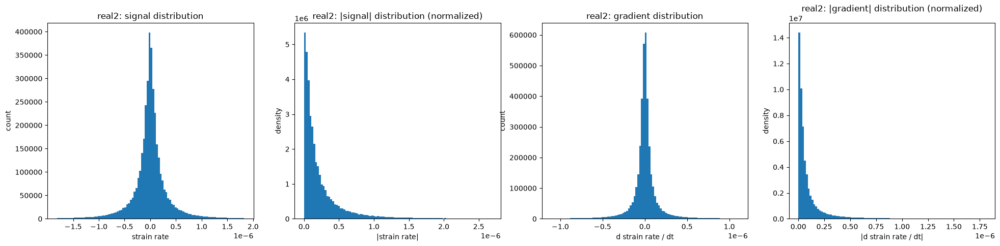

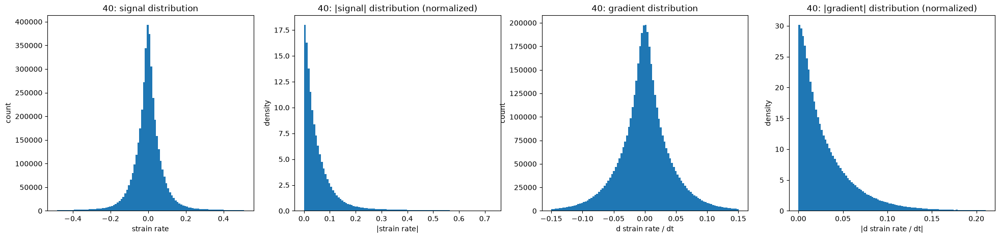

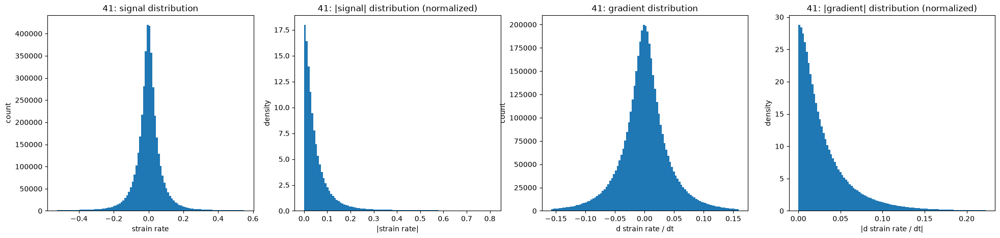

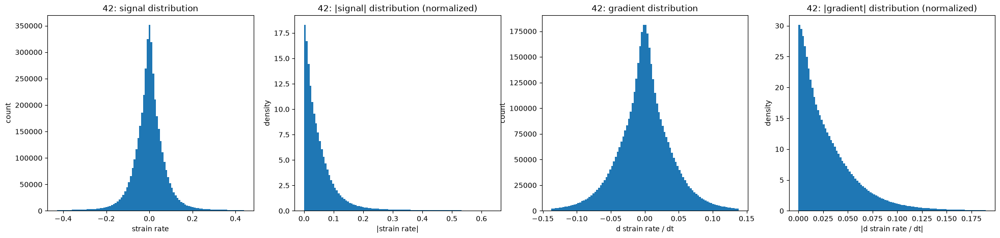

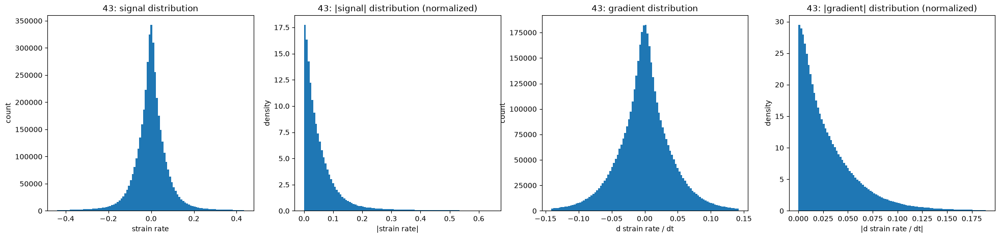

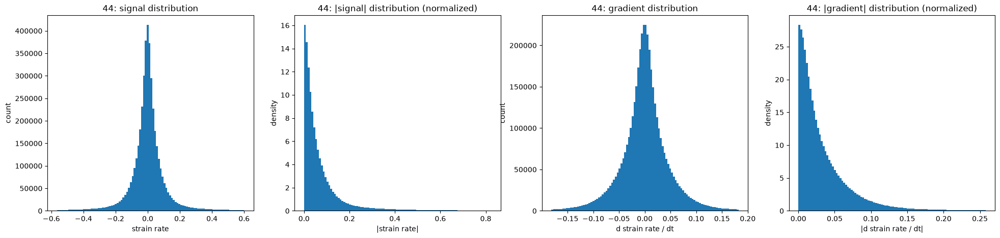

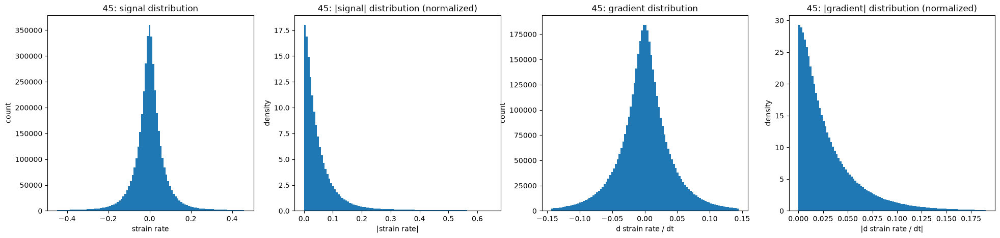

In [ ]:
for name, df in [('real', df_real), ('real2', df_real2)] + [(i, s['signal']) for i, s in synthetic.items()]:
    values = df.values.ravel()
    grad = np.gradient(df.values, axis=0).ravel()
    fig, axes = plt.subplots(1, 4, figsize=(24, 5))

    axes[0].hist(values, bins=100, range=np.percentile(values, [1, 99]))
    axes[0].set_title(f'{name}: signal distribution')
    axes[0].set_xlabel('strain rate')
    axes[0].set_ylabel('count')

    axes[1].hist(np.abs(values), bins=100, range=(0, np.percentile(np.abs(values), 99)), density=True)
    axes[1].set_title(f'{name}: |signal| distribution (normalized)')
    axes[1].set_xlabel('|strain rate|')
    axes[1].set_ylabel('density')

    axes[2].hist(grad, bins=100, range=np.percentile(grad, [1, 99]))
    axes[2].set_title(f'{name}: gradient distribution')
    axes[2].set_xlabel('d strain rate / dt')
    axes[2].set_ylabel('count')

    axes[3].hist(np.abs(grad), bins=100, range=(0, np.percentile(np.abs(grad), 99)), density=True)
    axes[3].set_title(f'{name}: |gradient| distribution (normalized)')
    axes[3].set_xlabel('|d strain rate / dt|')
    axes[3].set_ylabel('density')
    plt.show()

### 2.2 One channel over time

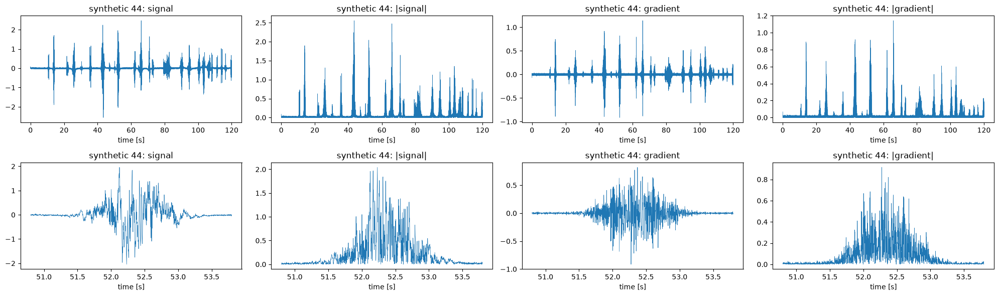

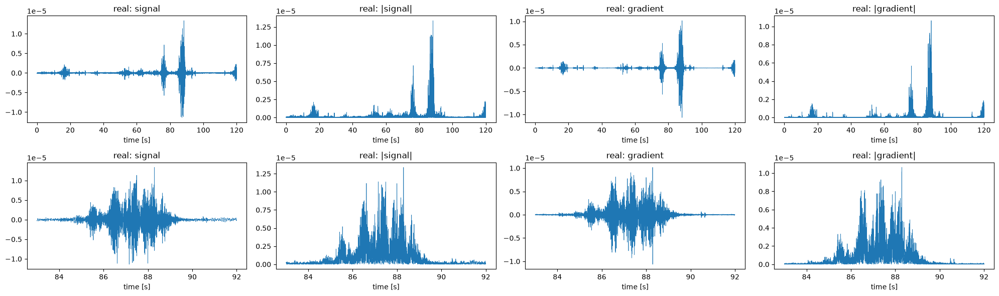

In [13]:
for name, df, start, end in [('synthetic 44', synthetic[44]['signal'], 50.8, 53.8), ('real', df_real, 83, 92)]:
    signal = df.values[:, 30]
    t = np.arange(len(signal)) * DT
    moment = slice(int(start / DT), int(end / DT))

    fig, axes = plt.subplots(2, 4, figsize=(20, 6))
    for row, part in zip(axes, [slice(None), moment]):
        for ax, values, title in zip(row, [signal, np.abs(signal), np.gradient(signal), np.abs(np.gradient(signal))],
                                     ['signal', '|signal|', 'gradient', '|gradient|']):
            ax.plot(t[part], values[part], linewidth=0.5)
            ax.set_title(f'{name}: {title}')
            ax.set_xlabel('time [s]')
    plt.tight_layout()
    plt.show()

### 2.3 Basic statistics

In [ ]:
examples = [('real', df_real), ('real2', df_real2)] + [(i, s['signal']) for i, s in synthetic.items()]
stats = {}
for name, df in examples:
    values = pd.Series(df.values.ravel())
    stats[name] = values.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).drop('count')
    stats[name]['skewness'] = values.skew()
    stats[name]['kurtosis'] = values.kurt()
stats = pd.DataFrame(stats).T
stats

,mean,std,min,1%,25%,50%,75%,99%,max,skewness,kurtosis
real,3.897971e-10,6.406182e-07,-0.000044,-0.000002,-1.002693e-07,0.000000,1.002693e-07,0.000002,0.000044,0.425749,248.987366
real2,1.462899e-10,7.003401e-07,-0.000042,-0.000002,-1.253367e-07,0.000000,1.228299e-07,0.000002,0.000041,0.409607,193.726044
40,2.688940e-06,1.568253e-01,-3.511621,-0.485144,-3.702102e-02,-0.000457,3.607688e-02,0.509410,4.429686,0.047237,44.797264
41,-8.208967e-05,1.704976e-01,-4.013488,-0.527232,-3.494275e-02,-0.000278,3.400257e-02,0.549106,5.107207,0.457485,52.263100
42,5.951707e-06,1.370354e-01,-3.187224,-0.429381,-3.647229e-02,0.000109,3.637622e-02,0.440039,3.481210,-0.368814,40.338173
43,-1.812190e-04,1.453119e-01,-3.239545,-0.441269,-3.745258e-02,-0.000241,3.690848e-02,0.435139,4.148851,0.735679,55.712666
44,-5.994507e-06,1.832160e-01,-3.956375,-0.565800,-4.139530e-02,-0.000828,3.981265e-02,0.599952,4.425092,-0.086813,39.605984
45,4.552043e-06,1.411520e-01,-3.303247,-0.449374,-3.500993e-02,-0.000155,3.485732e-02,0.457951,3.993452,-0.070638,40.579212


### 2.4 Variability across space

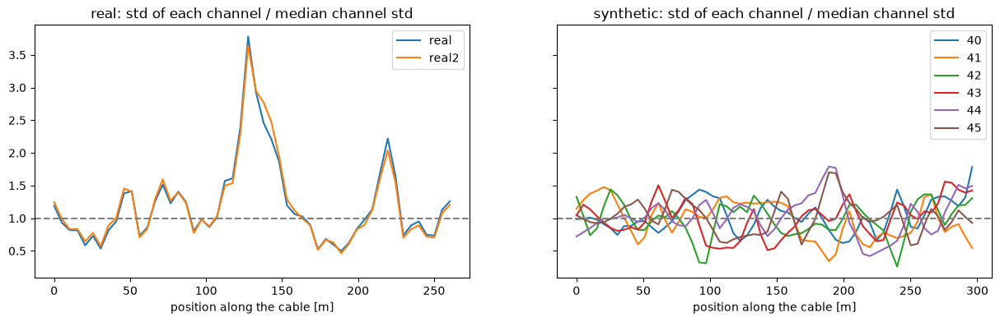

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for name, df in examples:
    std = df.std()
    ax = axes[0] if name in ('real', 'real2') else axes[1]
    ax.plot(std.index, std / std.median(), label=name)
for ax, title in zip(axes, ['real', 'synthetic']):
    ax.axhline(1, color='gray', linestyle='--')
    ax.set_title(f'{title}: std of each channel / median channel std')
    ax.set_xlabel('position along the cable [m]')
    ax.legend()
plt.show()

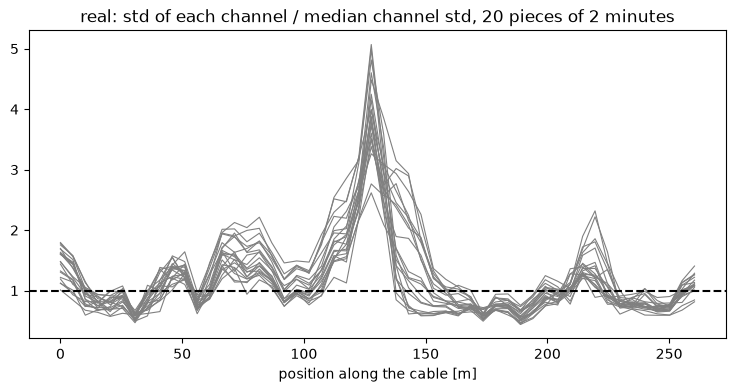

In [ ]:
real_files = [f for f in files if f[-10:-4] >= '090252']
plt.figure(figsize=(9, 4))
for start in range(0, len(real_files) - 11, 12):
    x = np.concatenate([np.load(f) for f in real_files[start:start + 12]])
    std = x.std(axis=0)
    plt.plot(df_real.columns, std / np.median(std), color='gray', linewidth=0.8)
plt.axhline(1, color='black', linestyle='--')
plt.title(f'real: std of each channel / median channel std, {len(real_files) // 12} pieces of 2 minutes')
plt.xlabel('position along the cable [m]')
plt.show()

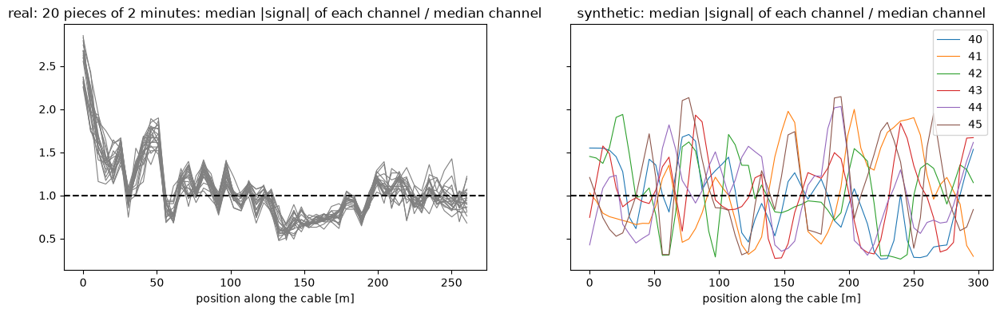

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for start in range(0, len(real_files) - 11, 12):
    x = np.abs(np.concatenate([np.load(f) for f in real_files[start:start + 12]]))
    median = np.median(x, axis=0)
    axes[0].plot(df_real.columns, median / np.median(median), color='gray', linewidth=0.8)
for i, s in synthetic.items():
    median = np.median(np.abs(s['signal'].values), axis=0)
    axes[1].plot(s['signal'].columns, median / np.median(median), linewidth=0.8, label=i)
for ax, title in zip(axes, ['real: 20 pieces of 2 minutes', 'synthetic']):
    ax.axhline(1, color='black', linestyle='--')
    ax.set_title(f'{title}: median |signal| of each channel / median channel')
    ax.set_xlabel('position along the cable [m]')
axes[1].legend()
plt.show()

### 2.5 Variability over time

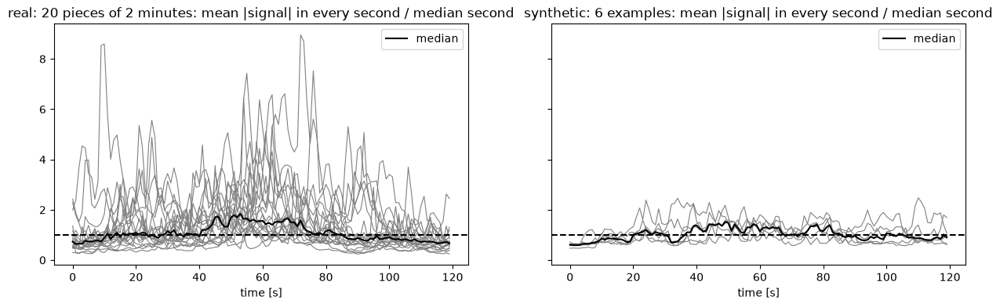

In [ ]:
def mean_per_second(x):
    return np.abs(x).reshape(-1, int(1 / DT), x.shape[1]).mean(axis=(1, 2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
real_files = [f for f in files if f[-10:-4] >= '090252']
pieces = [mean_per_second(np.concatenate([np.load(f) for f in real_files[k:k + 12]])) for k in range(0, len(real_files) - 11, 12)]
examples_mean = [mean_per_second(s['signal'].values) for s in synthetic.values()]
for ax, curves, title in zip(axes, [pieces, examples_mean], [f'real: {len(pieces)} pieces of 2 minutes', 'synthetic: 6 examples']):
    curves = np.array([c / np.median(c) for c in curves])
    for c in curves:
        ax.plot(c, color='gray', linewidth=0.8)
    ax.plot(np.median(curves, axis=0), color='black', linewidth=1.5, label='median')
    ax.axhline(1, color='black', linestyle='--')
    ax.set_title(f'{title}: mean |signal| in every second / median second')
    ax.set_xlabel('time [s]')
    ax.legend()
plt.show()

### 2.6 Vehicles versus background (synthetic only)

In [ ]:
parts = []
for i, s in synthetic.items():
    types = np.r_[['background'], s['vehicles']['type'].sort_index().values]     # marker 0 = background, 1.. = vehicles
    parts.append(pd.DataFrame({'|signal|': np.abs(s['signal'].values.ravel()), 'type': types[s['ground_truth'].values.ravel()]}))
parts = pd.concat(parts)

by_type = parts.groupby('type')['|signal|'].agg(['count', 'mean', 'median', 'std'])
by_type['share of pixels [%]'] = 100 * by_type['count'] / by_type['count'].sum()
by_type['median / background median'] = by_type['median'] / by_type.loc['background', 'median']
display(by_type.sort_values('median'))

,count,mean,median,std,share of pixels [%],median / background median
type,,,,,,
background,25168831,0.065703,0.034982,0.117509,94.797857,1.000000
car,920323,0.124749,0.071721,0.171110,3.466377,2.050239
van,67623,0.169482,0.105437,0.220468,0.254701,3.014063
truck,16509,0.283846,0.153700,0.438568,0.062181,4.393741
tram,376714,0.453596,0.336321,0.418538,1.418885,9.614205


In [ ]:
def evaluate(pred, gt):
    pred, gt = pred > 0, gt > 0
    tp = (pred & gt).sum()
    if tp == 0:
        return 0.0, 0.0, 0.0
    precision = tp / pred.sum()
    recall = tp / gt.sum()
    return precision, recall, 2 * precision * recall / (precision + recall)


PERCENTILES = np.r_[0:90:5, 90:100]


def predict(score, threshold, opening):
    pred = (score > threshold).astype(np.uint8)
    if opening:
        pred = cv2.morphologyEx(pred, cv2.MORPH_OPEN, np.ones((5, 1), np.uint8))
    return pred > 0


def roc(score, gt, opening):
    gt = gt > 0
    fpr, tpr, f1 = [], [], []
    for threshold in np.percentile(score, PERCENTILES):
        pred = predict(score, threshold, opening)
        fpr.append((pred & ~gt).sum() / (~gt).sum())
        tpr.append((pred & gt).sum() / gt.sum())
        f1.append(evaluate(pred, gt)[2])
    return np.array(fpr), np.array(tpr), np.array(f1)


def show_methods(methods):
    curves = {m: {i: roc(f(s['signal'].values), s['ground_truth'].values, opening) for i, s in synthetic.items()}
              for m, (f, opening) in methods.items()}
    best = {m: PERCENTILES[np.mean([c[2] for c in curves[m].values()], axis=0).argmax()] for m in methods}
    summary = pd.DataFrame({m: {'best percentile': best[m],
                                'mean F1': np.mean([c[2][PERCENTILES == best[m]][0] for c in curves[m].values()]),
                                'mean AUC': np.mean([np.trapezoid(np.r_[0, c[1][::-1]], np.r_[0, c[0][::-1]]) for c in curves[m].values()])}
                            for m in methods}).T
    display(summary.round(3))

    for name, df in [('real', df_real), ('real2', df_real2)] + [(i, s['signal']) for i, s in synthetic.items()]:
        widths = [1] * len(methods) + ([] if name == 'real' or name == 'real2' else [2, 1])
        ncols = (sum(widths) + 1) // 2
        fig = plt.figure(figsize=(4 * ncols, 20))
        grid = fig.add_gridspec(2, ncols)
        axes, row_starts, row, col = [], [], 0, 0
        for w in widths:
            if col + w > ncols:
                row, col = row + 1, 0
            axes.append(fig.add_subplot(grid[row, col:col + w]))
            if col == 0:
                row_starts.append(axes[-1])
            col += w
        images = axes[:len(methods)]

        for ax, (m, (f, opening)) in zip(axes, methods.items()):
            score = f(df.values)
            ax.imshow(predict(score, np.percentile(score, best[m]), opening), interpolation='antialiased', aspect='auto')
            ax.set_title(f'{name}: {m} > {best[m]}th')

        if name != 'real' and name != 'real2':
            for m in methods:
                fpr, tpr, f1 = curves[m][name]
                k = PERCENTILES == best[m]
                auc = np.trapezoid(np.r_[0, tpr[::-1]], np.r_[0, fpr[::-1]])
                line, = axes[-2].plot(fpr, tpr, marker='.', label=f'{m} (AUC {auc:.2f}, F1 {f1[k][0]:.2f})')
                axes[-2].scatter(fpr[k], tpr[k], s=80, color=line.get_color(), edgecolor='k', zorder=3)
            axes[-2].plot([0, 1], [0, 1], 'k--')
            axes[-2].set_box_aspect(1)
            axes[-2].set_xlabel('false positive rate')
            axes[-2].set_ylabel('true positive rate')
            axes[-2].set_title(f'{name}: ROC (dot = best percentile)')
            axes[-2].legend(fontsize=9, loc='lower right')
            axes[-1].imshow(synthetic[name]['ground_truth'], interpolation='none', aspect='auto', cmap='nipy_spectral')
            axes[-1].set_title(f'{name}: ground truth')
            images.append(axes[-1])

        x_positions, x_labels = set_axis(df.columns)
        y_positions, y_labels = set_axis(df.index.time if  name == 'real' or name == 'real2' else np.round(df.index, 1))
        for ax in images:
            ax.set_xticks(x_positions, np.round(x_labels))
            ax.set_xlabel('space [m]')
            ax.set_yticks(y_positions, y_labels)
        for ax in row_starts:
            ax.set_ylabel('time')
        plt.tight_layout()
        plt.show()

# Methods

For each method that is using percentiles, I am checking which is giving highest F1 and I am taking this as threshold

Methods used for now:
- **abs** - absolute value of the signal above threshold
- **abs - median** - abs but first I subtract median of each column to reduce noise
- **abs / median** - abs but first I divide median of each column to reduce noise
- **grad** - absolute value of gradient in time above threshold
- **grad - median** - grad but first I subtract median of each column to reduce noise
- **grad / median** - grad but first I divide median of each column to reduce noise
- **grad + opening 5x1** - grad above percentile and then opening with kernel 5 x 1
- **grad - median + opening 5x1** - grad - median then opening 5x1
- **grad / median + opening 5x1** - grad / median, then opening 5x1

best is **abs / median** - can be taken as the base for the next steps

,best percentile,mean F1,mean AUC
abs,93.0,0.274,0.734
abs - median,92.0,0.283,0.733
abs / median,91.0,0.295,0.741
grad,94.0,0.198,0.652
grad - median,94.0,0.213,0.652
grad / median,94.0,0.244,0.661
grad + opening 5x1,75.0,0.205,0.666
grad - median + opening 5x1,70.0,0.240,0.654
grad / median + opening 5x1,70.0,0.252,0.677


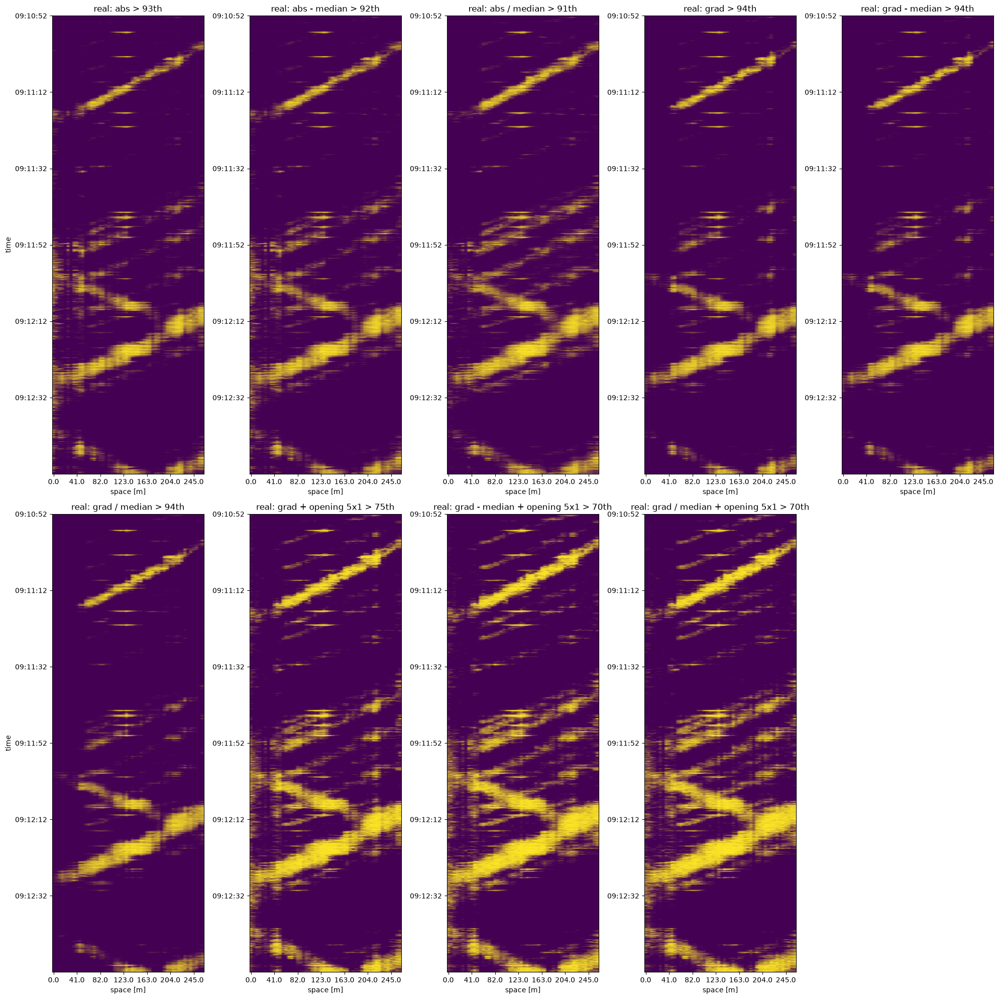

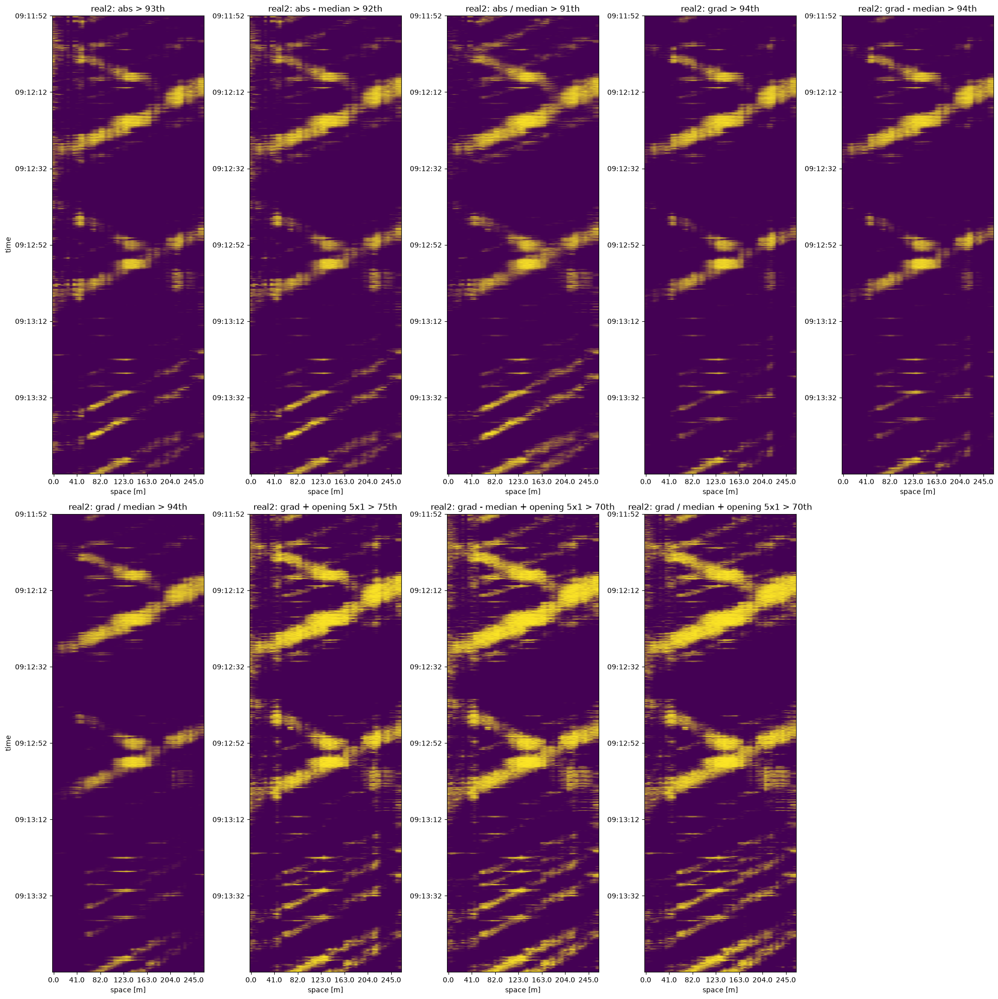

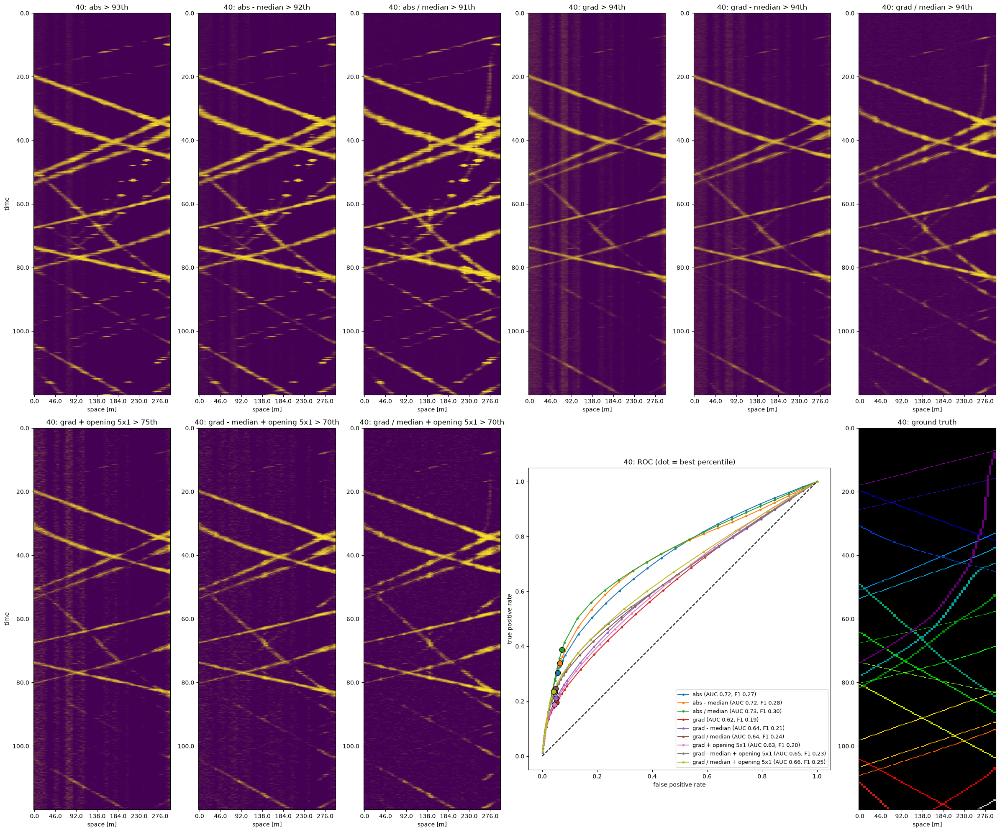

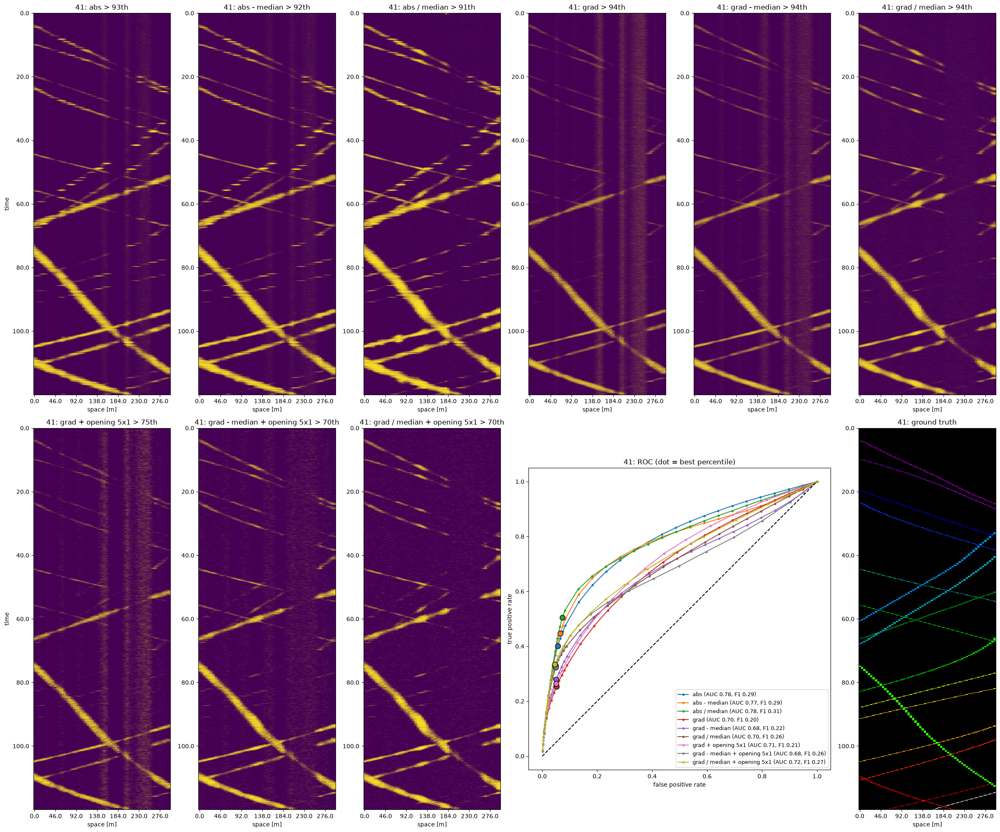

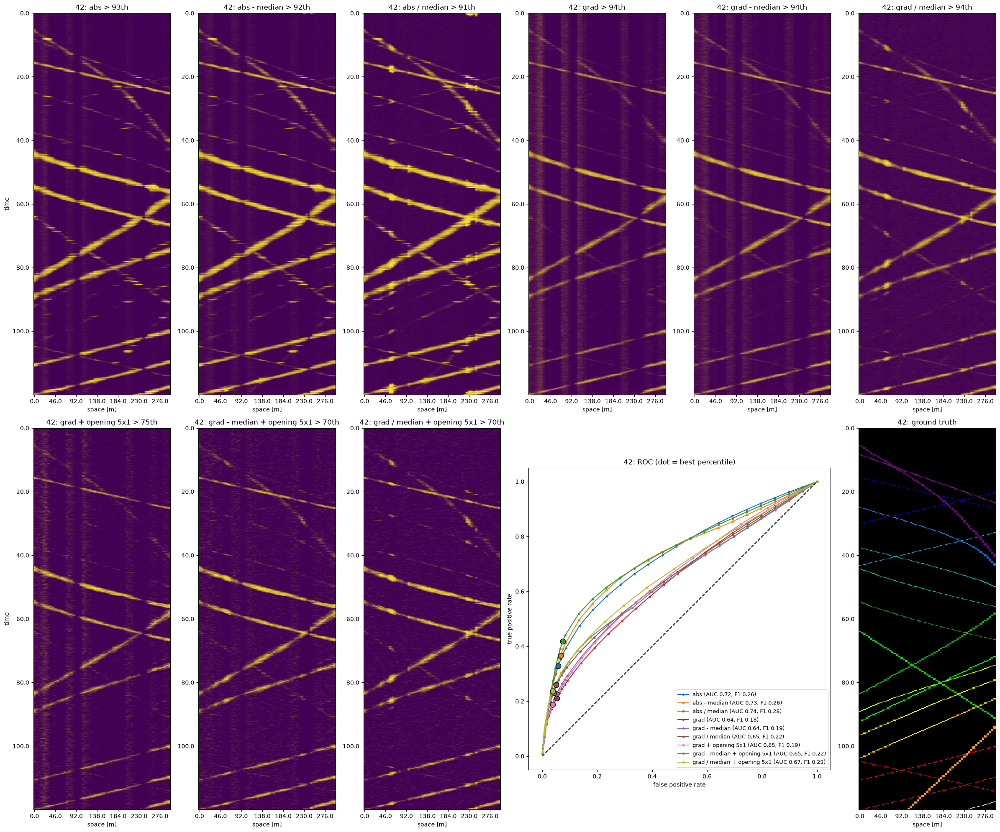

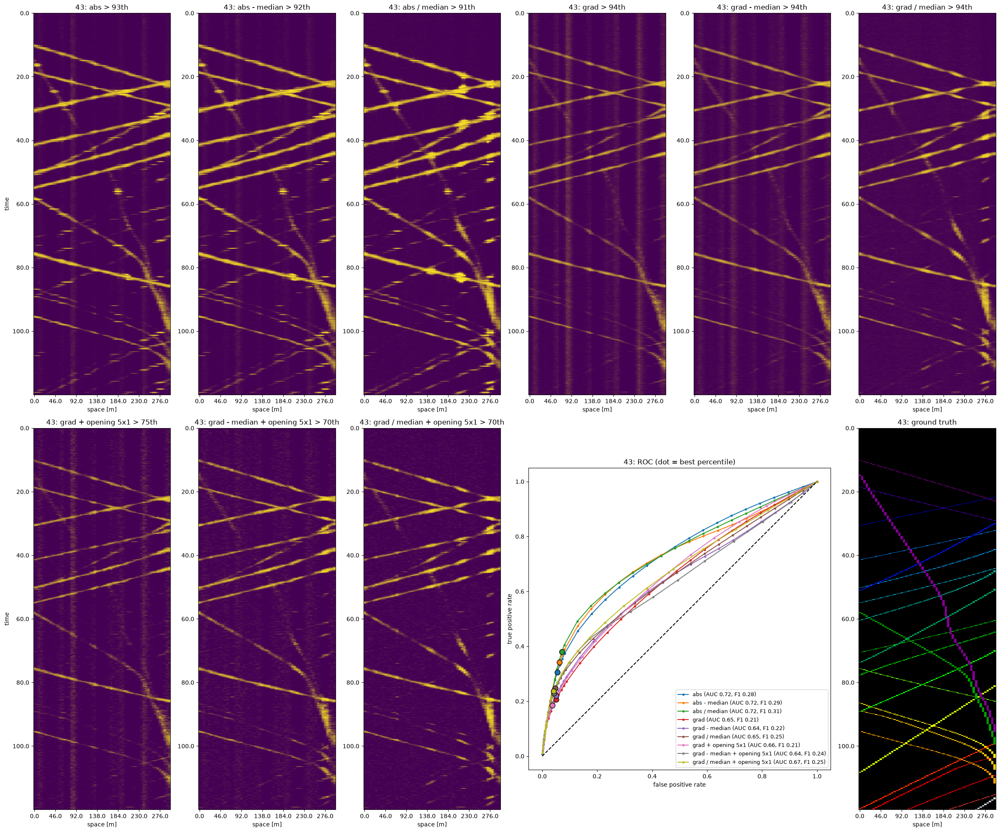

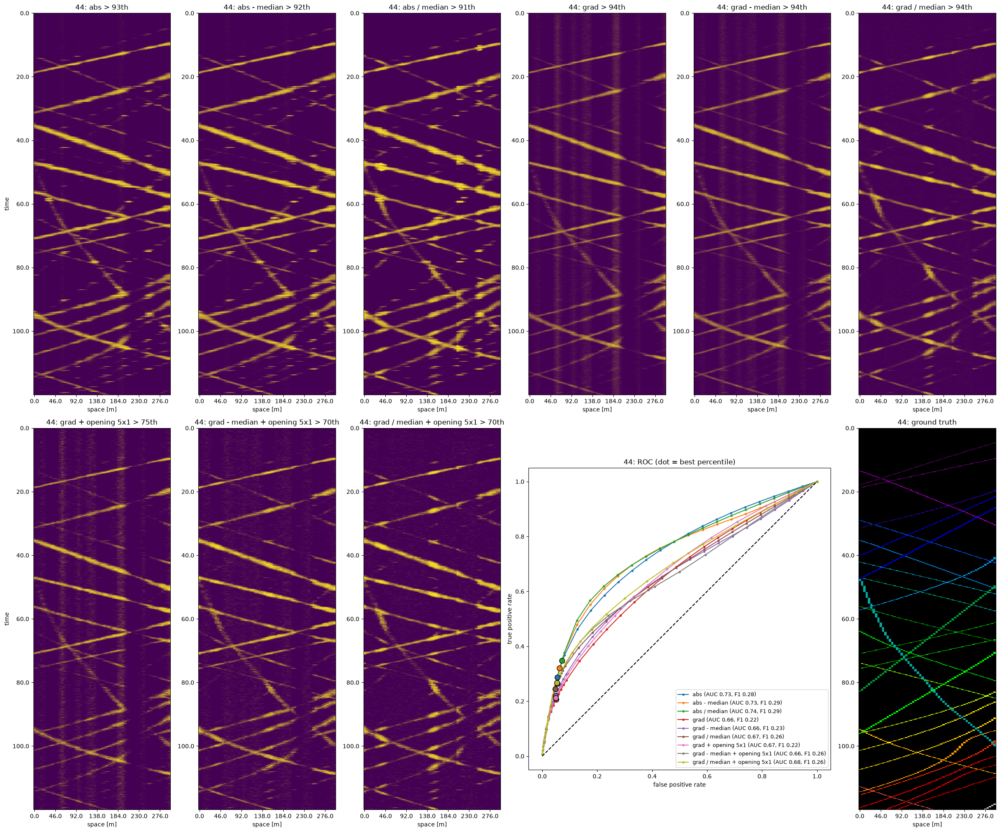

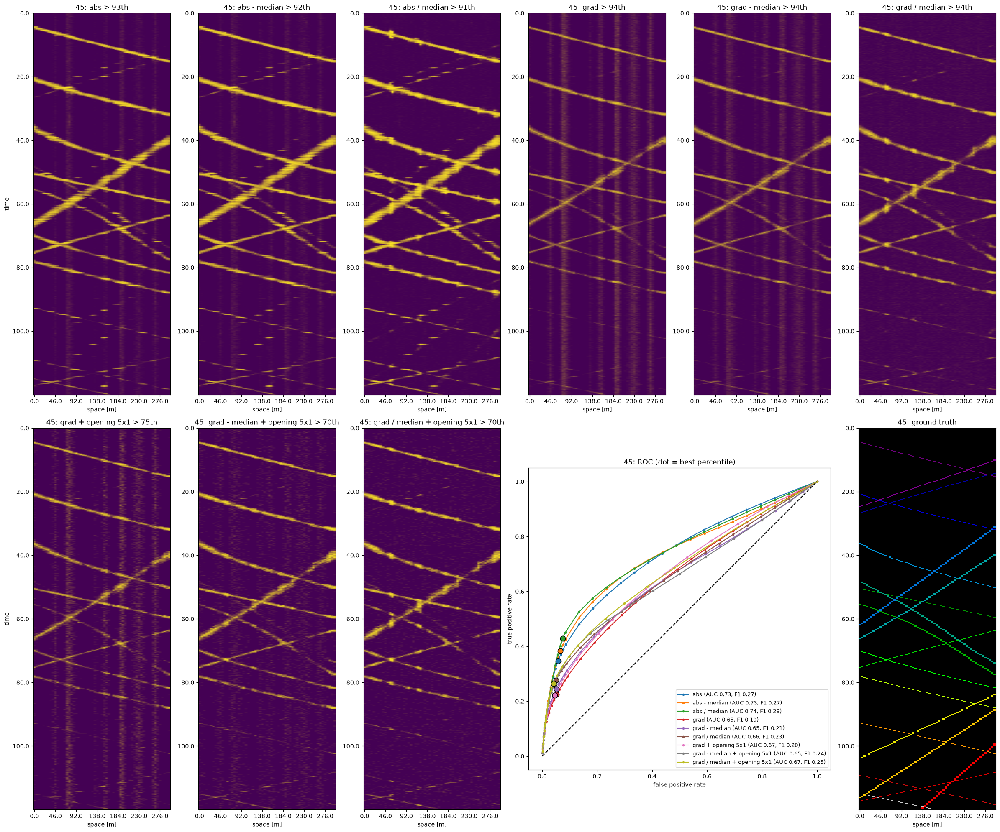

In [221]:
def minus_column_median(x):
    return x - np.median(x, axis=0)


def divide_by_column_median(x):
    return x / np.median(x, axis=0)


show_methods({
    'abs': (lambda x: np.abs(x), False),
    'abs - median': (lambda x: minus_column_median(np.abs(x)), False),
    'abs / median': (lambda x: divide_by_column_median(np.abs(x)), False),
    'grad': (lambda x: np.abs(np.gradient(x, axis=0)), False),
    'grad - median': (lambda x: minus_column_median(np.abs(np.gradient(x, axis=0))), False),
    'grad / median': (lambda x: divide_by_column_median(np.abs(np.gradient(x, axis=0))), False),
    'grad + opening 5x1': (lambda x: np.abs(np.gradient(x, axis=0)), True),
    'grad - median + opening 5x1': (lambda x: minus_column_median(np.abs(np.gradient(x, axis=0))), True),
    'grad / median + opening 5x1': (lambda x: divide_by_column_median(np.abs(np.gradient(x, axis=0))), True),
})